In [1]:
'''
项目目标

## 本阶段解决的问题

前一阶段完成了区域级occupancy指标计算
但TAZID仅为区域编号，无法直接体现地理位置。

本阶段将occupancy统计结果与深圳区域空间边界数据进行关联，
构建空间分析数据，为后续地图可视化提供基础。


## 使用数据

1. occupancy区域统计结果
2. 深圳TAZ区域边界数据（SZ_districts）


## 输出

1. 带有occupancy指标的空间数据
2. 区域空间分布可视化基础数据
'''

'\n项目目标\n\n## 本阶段解决的问题\n\n前一阶段完成了区域级occupancy指标计算\n但TAZID仅为区域编号，无法直接体现地理位置。\n\n本阶段将occupancy统计结果与深圳区域空间边界数据进行关联，\n构建空间分析数据，为后续地图可视化提供基础。\n\n\n## 使用数据\n\n1. occupancy区域统计结果\n2. 深圳TAZ区域边界数据（SZ_districts）\n\n\n## 输出\n\n1. 带有occupancy指标的空间数据\n2. 区域空间分布可视化基础数据\n'

In [2]:
import pandas as pd
import geopandas as gpd
# 区域occupancy结果
zone_occupancy = pd.read_csv(
    "../dataset/processed/zone_occupancy.csv"
)


# 深圳区域边界
districts = gpd.read_file(
    "../dataset/SZ_districts/SZ_districts.shp"
)
zone_occupancy


,TAZID,occupancy
0,102,14.207873
1,104,1.196478
2,105,17.774056
3,106,49.159876
4,107,17.214434
...,...,...
270,1166,23.478591
271,1167,137.304558
272,1168,8.238605
273,1172,3.131906


In [3]:
districts.head(5)

,OBJECTID,TAZID,AREA,X,Y,ZONE,LENG_ROAD,SHAPE_Leng,SHAPE_Area,geometry
0,1,1054.0,11.49,114.333530,22.783052,781.0,10.135,25856.846986,13581804.0,"POLYGON ((12727715 2609219, 12727838 2609098, ..."
1,2,1052.0,17.07,114.282465,22.789111,775.0,6.368,30117.841314,20191527.5,"POLYGON ((12721609 2609078, 12721630 2608932, ..."
2,3,850.0,2.85,114.322722,22.791482,780.0,4.822,10307.116136,3375499.0,"POLYGON ((12726477 2609132, 12726623 2609056, ..."
3,4,1066.0,1.57,113.910301,22.521287,307.0,7.130,5552.707185,1857995.0,"POLYGON ((12680558 2573496, 12680096 2573463, ..."
4,5,1068.0,1.41,113.918680,22.517837,306.0,7.084,5930.667262,1654644.0,"POLYGON ((12681747 2573552, 12681409 2572621, ..."


In [4]:
districts.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 491 entries, 0 to 490
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   OBJECTID    491 non-null    int64   
 1   TAZID       491 non-null    float64 
 2   AREA        491 non-null    float64 
 3   X           491 non-null    float64 
 4   Y           491 non-null    float64 
 5   ZONE        491 non-null    float64 
 6   LENG_ROAD   491 non-null    float64 
 7   SHAPE_Leng  491 non-null    float64 
 8   SHAPE_Area  491 non-null    float64 
 9   geometry    491 non-null    geometry
dtypes: float64(8), geometry(1), int64(1)
memory usage: 38.5 KB


In [5]:
zone_occupancy.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 275 entries, 0 to 274
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TAZID      275 non-null    int64  
 1   occupancy  275 non-null    float64
dtypes: float64(1), int64(1)
memory usage: 4.4 KB


In [6]:
districts["TAZID"] = districts["TAZID"].astype(int)

In [7]:
districts.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 491 entries, 0 to 490
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   OBJECTID    491 non-null    int64   
 1   TAZID       491 non-null    int64   
 2   AREA        491 non-null    float64 
 3   X           491 non-null    float64 
 4   Y           491 non-null    float64 
 5   ZONE        491 non-null    float64 
 6   LENG_ROAD   491 non-null    float64 
 7   SHAPE_Leng  491 non-null    float64 
 8   SHAPE_Area  491 non-null    float64 
 9   geometry    491 non-null    geometry
dtypes: float64(7), geometry(1), int64(2)
memory usage: 38.5 KB


In [8]:
districts["TAZID"].nunique()

491

In [9]:
zone_occupancy["TAZID"].nunique()

275

In [10]:
districts_analysis = districts.merge(
    zone_occupancy,
    on="TAZID",
    how="left"
)

#左表是研究对象
districts_analysis.head(5)

,OBJECTID,TAZID,AREA,X,Y,ZONE,LENG_ROAD,SHAPE_Leng,SHAPE_Area,geometry,occupancy
0,1,1054,11.49,114.333530,22.783052,781.0,10.135,25856.846986,13581804.0,"POLYGON ((12727715 2609219, 12727838 2609098, ...",NaN
1,2,1052,17.07,114.282465,22.789111,775.0,6.368,30117.841314,20191527.5,"POLYGON ((12721609 2609078, 12721630 2608932, ...",NaN
2,3,850,2.85,114.322722,22.791482,780.0,4.822,10307.116136,3375499.0,"POLYGON ((12726477 2609132, 12726623 2609056, ...",NaN
3,4,1066,1.57,113.910301,22.521287,307.0,7.130,5552.707185,1857995.0,"POLYGON ((12680558 2573496, 12680096 2573463, ...",7.612454
4,5,1068,1.41,113.918680,22.517837,306.0,7.084,5930.667262,1654644.0,"POLYGON ((12681747 2573552, 12681409 2572621, ...",64.189572


In [11]:
districts_analysis.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 491 entries, 0 to 490
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   OBJECTID    491 non-null    int64   
 1   TAZID       491 non-null    int64   
 2   AREA        491 non-null    float64 
 3   X           491 non-null    float64 
 4   Y           491 non-null    float64 
 5   ZONE        491 non-null    float64 
 6   LENG_ROAD   491 non-null    float64 
 7   SHAPE_Leng  491 non-null    float64 
 8   SHAPE_Area  491 non-null    float64 
 9   geometry    491 non-null    geometry
 10  occupancy   275 non-null    float64 
dtypes: float64(8), geometry(1), int64(2)
memory usage: 42.3 KB


In [12]:
districts_analysis["occupancy"].isna().sum()

np.int64(216)

In [13]:
districts_analysis.shape

(491, 11)

In [14]:
'''
## 空间关联结果检查

深圳TAZ空间边界数据包含491个区域。

UrbanEV数据集中的occupancy指标覆盖275个TAZ区域。

将两类数据按照TAZID进行关联后，
共保留491个空间区域，其中216个区域不存在occupancy记录。

由于官方数据说明该数据集覆盖275个区域，
因此缺失区域不代表occupancy为0，
更可能表示该区域没有对应的EV充电设施数据覆盖。

后续可视化分析中需区分：
- 有occupancy数据区域
- 无occupancy数据区域
'''

'\n## 空间关联结果检查\n\n深圳TAZ空间边界数据包含491个区域。\n\nUrbanEV数据集中的occupancy指标覆盖275个TAZ区域。\n\n将两类数据按照TAZID进行关联后，\n共保留491个空间区域，其中216个区域不存在occupancy记录。\n\n由于官方数据说明该数据集覆盖275个区域，\n因此缺失区域不代表occupancy为0，\n更可能表示该区域没有对应的EV充电设施数据覆盖。\n\n后续可视化分析中需区分：\n- 有occupancy数据区域\n- 无occupancy数据区域\n'

In [15]:
districts_analysis[
    districts_analysis["occupancy"].notna()
].sort_values(
    "occupancy",
    ascending=False
)[
    ["TAZID","occupancy"]
].head(10)

,TAZID,occupancy
181,1167,137.304558
350,526,102.887891
267,519,87.164825
130,1011,82.056860
427,703,80.162178
297,335,76.468692
105,1049,74.671961
362,633,70.684162
150,851,65.610497
4,1068,64.189572


In [16]:
districts_analysis.columns

Index(['OBJECTID', 'TAZID', 'AREA', 'X', 'Y', 'ZONE', 'LENG_ROAD',
       'SHAPE_Leng', 'SHAPE_Area', 'geometry', 'occupancy'],
      dtype='object')

In [17]:
districts_analysis["occupancy"].isna().sum()

np.int64(216)

In [18]:
districts_analysis[
    districts_analysis["TAZID"]==1167
]

,OBJECTID,TAZID,AREA,X,Y,ZONE,LENG_ROAD,SHAPE_Leng,SHAPE_Area,geometry,occupancy
181,182,1167,6.13,114.145276,22.599219,713.0,8.475,19597.149214,7230914.0,"POLYGON ((12709466 2585802, 12709363 2585740, ...",137.304558


In [19]:
import pandas as pd

inf = pd.read_csv("../dataset/UrbanEV/inf.csv")

inf["TAZID"] = inf["TAZID"].astype(int)

zone_charge = (
    inf.groupby("TAZID")["charge_count"]
    .sum()
    .sort_values(ascending=False)
)

zone_charge

TAZID
1167    373
1011    332
526     262
329     254
335     249
       ... 
852       8
719       6
628       6
792       6
316       4
Name: charge_count, Length: 275, dtype: int64

In [20]:
analysis_df = pd.merge(
    zone_occupancy,
    zone_charge,
    on="TAZID"
)
analysis_df.corr()
#关联系数矩阵：在当前样本区域内，occupancy与charge_count呈现较强正相关关系，即设施数量较多的区域通常也具有较高的充电活跃水平

,TAZID,occupancy,charge_count
TAZID,1.000000,0.011142,-0.007854
occupancy,0.011142,1.000000,0.921999
charge_count,-0.007854,0.921999,1.000000


In [21]:
analysis_df.sort_values(
    ["occupancy","charge_count"],
    ascending=[False,True]
).head(20)

,TAZID,occupancy,charge_count
271,1167,137.304558,373
67,526,102.887891,262
63,519,87.164825,223
207,1011,82.056860,332
118,703,80.162178,233
47,335,76.468692,249
213,1049,74.671961,200
97,633,70.684162,135
162,851,65.610497,142
219,1068,64.189572,227


In [22]:
#目前初步发现EV充电活动指标较高的区域通常伴随着较高的充电设施数量

In [23]:
analysis_df.sort_values(
    by="charge_count",
    ascending=True
).head(20)

,TAZID,occupancy,charge_count
33,316,1.929788,4
94,628,1.909070,6
130,719,3.106814,6
150,792,2.502072,6
163,852,2.395373,8
114,698,3.744936,9
103,651,6.320902,9
19,214,1.162523,9
273,1172,3.131906,9
31,310,2.154466,10


In [24]:
'''
# 发现：
低占用区域通常对应较少的充电设施数量，未发现明显的“低供给、高需求”区域。

# 初步判断：
当前数据范围内，充电设施数量与区域充电活动水平存在较强匹配关系，低设施区域暂未表现出明显供给不足。

# 注意：
该结论仅基于区域平均occupancy指标，不代表不存在时间高峰期供需压力。
后续需要结合小时级时序数据进一步验证。
'''

'\n# 发现：\n低占用区域通常对应较少的充电设施数量，未发现明显的“低供给、高需求”区域。\n\n# 初步判断：\n当前数据范围内，充电设施数量与区域充电活动水平存在较强匹配关系，低设施区域暂未表现出明显供给不足。\n\n# 注意：\n该结论仅基于区域平均occupancy指标，不代表不存在时间高峰期供需压力。\n后续需要结合小时级时序数据进一步验证。\n'

In [25]:
avg_occ = analysis_df["occupancy"].mean()
avg_charge = analysis_df["charge_count"].mean()

potential_low_efficiency = analysis_df[
    (analysis_df["charge_count"] > avg_charge)
    &
    (analysis_df["occupancy"] < avg_occ)
]

potential_low_efficiency.sort_values(
    "charge_count",
    ascending=False
).head(10)

,TAZID,occupancy,charge_count
239,1102,17.857274,104
216,1062,16.480548,102
215,1061,16.881906,99
208,1015,17.256331,96
2,105,17.774056,93
250,1119,16.425069,93
251,1120,15.818140,91
109,686,11.058011,89
4,107,17.214434,88
8,111,17.722606,85


In [26]:
#day3

In [27]:
analysis_df["demand_level"] = (
    analysis_df["occupancy"]
    > avg_occ
)

analysis_df["supply_level"] = (
    analysis_df["charge_count"]
    > avg_charge
)


In [28]:
def classify(row):
    if row["demand_level"] and not row["supply_level"]:
        return "高需求低供给"
    
    elif row["demand_level"] and row["supply_level"]:
        return "高需求高供给"
    
    elif not row["demand_level"] and row["supply_level"]:
        return "低需求高供给"
    
    else:
        return "低需求低供给"


analysis_df["type"] = analysis_df.apply(
    classify,
    axis=1
)

In [29]:
analysis_df[
    analysis_df["type"]=="高需求低供给"
]

,TAZID,occupancy,charge_count,demand_level,supply_level,type
50,346,23.417357,61,True,False,高需求低供给
55,501,21.692680,47,True,False,高需求低供给
91,596,31.966851,55,True,False,高需求低供给
113,693,22.257136,59,True,False,高需求低供给
194,981,20.212477,49,True,False,高需求低供给
210,1029,29.551565,36,True,False,高需求低供给
236,1098,25.844613,60,True,False,高需求低供给
253,1124,27.878223,61,True,False,高需求低供给


In [30]:
avg_occ = analysis_df["occupancy"].mean()
avg_charge = analysis_df["charge_count"].mean()

print("平均occupancy: {:.2f}".format(avg_occ))
print("平均charge_count: {:.2f}".format(avg_charge))

平均occupancy: 17.87
平均charge_count: 63.75


In [31]:
#接下来是四象限 回答深圳新能源充电设施布局是否与区域需求匹配

In [32]:
def classify(row):
    if row["occupancy"] >= avg_occ and row["charge_count"] < avg_charge:
        return "高需求低供给"
    
    elif row["occupancy"] >= avg_occ and row["charge_count"] >= avg_charge:
        return "高需求高供给"
    
    elif row["occupancy"] < avg_occ and row["charge_count"] >= avg_charge:
        return "低需求高供给"
    
    else:
        return "低需求低供给"


analysis_df["supply_demand_type"] = analysis_df.apply(
    classify,
    axis=1
)

In [33]:
analysis_df["supply_demand_type"].value_counts()


supply_demand_type
低需求低供给    169
高需求高供给     75
低需求高供给     23
高需求低供给      8
Name: count, dtype: int64

In [34]:
#从区域平均尺度来看，大部分区域的充电需求水平与设施数量保持一致，没有出现大规模供需错配现象。

In [35]:
high_need_low_supply = analysis_df[
    analysis_df["supply_demand_type"]=="高需求低供给"
]


high_need_low_supply.sort_values(
    "occupancy",
    ascending=False
)

,TAZID,occupancy,charge_count,demand_level,supply_level,type,supply_demand_type
91,596,31.966851,55,True,False,高需求低供给,高需求低供给
210,1029,29.551565,36,True,False,高需求低供给,高需求低供给
253,1124,27.878223,61,True,False,高需求低供给,高需求低供给
236,1098,25.844613,60,True,False,高需求低供给,高需求低供给
50,346,23.417357,61,True,False,高需求低供给,高需求低供给
113,693,22.257136,59,True,False,高需求低供给,高需求低供给
55,501,21.692680,47,True,False,高需求低供给,高需求低供给
194,981,20.212477,49,True,False,高需求低供给,高需求低供给


In [36]:
low_need_high_supply = analysis_df[
    analysis_df["supply_demand_type"]=="低需求高供给"
]


low_need_high_supply.sort_values(
    "charge_count",
    ascending=False
)

,TAZID,occupancy,charge_count,demand_level,supply_level,type,supply_demand_type
239,1102,17.857274,104,False,True,低需求高供给,低需求高供给
216,1062,16.480548,102,False,True,低需求高供给,低需求高供给
215,1061,16.881906,99,False,True,低需求高供给,低需求高供给
208,1015,17.256331,96,False,True,低需求高供给,低需求高供给
2,105,17.774056,93,False,True,低需求高供给,低需求高供给
250,1119,16.425069,93,False,True,低需求高供给,低需求高供给
251,1120,15.818140,91,False,True,低需求高供给,低需求高供给
109,686,11.058011,89,False,True,低需求高供给,低需求高供给
4,107,17.214434,88,False,True,低需求高供给,低需求高供给
8,111,17.722606,85,False,True,低需求高供给,低需求高供给


In [37]:
analysis_df.shape

(275, 7)

In [38]:
districts.shape

(491, 10)

In [39]:
districts.merge(
    analysis_df,
    on="TAZID",
    how="left"
)

,OBJECTID,TAZID,AREA,X,Y,ZONE,LENG_ROAD,SHAPE_Leng,SHAPE_Area,geometry,occupancy,charge_count,demand_level,supply_level,type,supply_demand_type
0,1,1054,11.49,114.333530,22.783052,781.0,10.135,25856.846986,13581804.0,"POLYGON ((12727715 2609219, 12727838 2609098, ...",NaN,NaN,NaN,NaN,NaN,NaN
1,2,1052,17.07,114.282465,22.789111,775.0,6.368,30117.841314,20191527.5,"POLYGON ((12721609 2609078, 12721630 2608932, ...",NaN,NaN,NaN,NaN,NaN,NaN
2,3,850,2.85,114.322722,22.791482,780.0,4.822,10307.116136,3375499.0,"POLYGON ((12726477 2609132, 12726623 2609056, ...",NaN,NaN,NaN,NaN,NaN,NaN
3,4,1066,1.57,113.910301,22.521287,307.0,7.130,5552.707185,1857995.0,"POLYGON ((12680558 2573496, 12680096 2573463, ...",7.612454,40.0,False,False,低需求低供给,低需求低供给
4,5,1068,1.41,113.918680,22.517837,306.0,7.084,5930.667262,1654644.0,"POLYGON ((12681747 2573552, 12681409 2572621, ...",64.189572,227.0,True,True,高需求高供给,高需求高供给
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
486,487,941,11.22,114.558370,22.617653,830.0,0.000,32266.003804,13227019.0,"POLYGON ((12756192 2590194, 12756219 2590186, ...",NaN,NaN,NaN,NaN,NaN,NaN
487,488,902,4.50,114.355630,22.712196,804.0,0.000,10818.341390,5320351.0,"POLYGON ((12729111 2596043, 12728621 2595461, ...",7.285451,70.0,False,True,低需求高供给,低需求高供给
488,489,974,3.64,114.144484,22.615399,710.0,9.146,8761.589269,4298492.5,"POLYGON ((12707932 2585276, 12707971 2584805, ...",49.886971,123.0,True,True,高需求高供给,高需求高供给
489,490,1154,1.23,114.224404,22.551290,401.0,9.541,5918.395932,1454578.0,"POLYGON ((12715562 2576929, 12715385 2576903, ...",3.413329,22.0,False,False,低需求低供给,低需求低供给


In [40]:
map_df = districts.merge(
    analysis_df,
    on="TAZID",
    how="left"
)
map_df.head()

,OBJECTID,TAZID,AREA,X,Y,ZONE,LENG_ROAD,SHAPE_Leng,SHAPE_Area,geometry,occupancy,charge_count,demand_level,supply_level,type,supply_demand_type
0,1,1054,11.49,114.333530,22.783052,781.0,10.135,25856.846986,13581804.0,"POLYGON ((12727715 2609219, 12727838 2609098, ...",NaN,NaN,NaN,NaN,NaN,NaN
1,2,1052,17.07,114.282465,22.789111,775.0,6.368,30117.841314,20191527.5,"POLYGON ((12721609 2609078, 12721630 2608932, ...",NaN,NaN,NaN,NaN,NaN,NaN
2,3,850,2.85,114.322722,22.791482,780.0,4.822,10307.116136,3375499.0,"POLYGON ((12726477 2609132, 12726623 2609056, ...",NaN,NaN,NaN,NaN,NaN,NaN
3,4,1066,1.57,113.910301,22.521287,307.0,7.130,5552.707185,1857995.0,"POLYGON ((12680558 2573496, 12680096 2573463, ...",7.612454,40.0,False,False,低需求低供给,低需求低供给
4,5,1068,1.41,113.918680,22.517837,306.0,7.084,5930.667262,1654644.0,"POLYGON ((12681747 2573552, 12681409 2572621, ...",64.189572,227.0,True,True,高需求高供给,高需求高供给


In [41]:
map_df.shape

(491, 16)

In [42]:
map_analysis = map_df.dropna(
    subset=["supply_demand_type"]
)

In [43]:
map_analysis.shape

(275, 16)

In [44]:
map_analysis = map_df.dropna(
    subset=["supply_demand_type"]
)

print(map_analysis.shape)

print(
    map_analysis["supply_demand_type"].value_counts()
)

(275, 16)
supply_demand_type
低需求低供给    169
高需求高供给     75
低需求高供给     23
高需求低供给      8
Name: count, dtype: int64


In [45]:
high_demand_low_supply = map_analysis[
    map_analysis["supply_demand_type"]=="高需求低供给"
]


high_demand_low_supply[
    [
        "TAZID",
        "occupancy",
        "charge_count"
    ]
].sort_values(
    "occupancy",
    ascending=False
)

,TAZID,occupancy,charge_count
463,596,31.966851,55.0
243,1029,29.551565,36.0
204,1124,27.878223,61.0
17,1098,25.844613,60.0
298,346,23.417357,61.0
396,693,22.257136,59.0
19,501,21.692680,47.0
73,981,20.212477,49.0


In [46]:
opportunity_area = map_analysis[
    map_analysis["supply_demand_type"]=="高需求低供给"
]


opportunity_area[
    [
        "TAZID",
        "occupancy",
        "charge_count",
        "geometry"
    ]
]

,TAZID,occupancy,charge_count,geometry
17,1098,25.844613,60.0,"POLYGON ((12679475 2578095, 12679094 2577749, ..."
19,501,21.692680,47.0,"POLYGON ((12677831 2579062, 12679094 2577749, ..."
73,981,20.212477,49.0,"POLYGON ((12712554 2588871, 12712010 2588363, ..."
204,1124,27.878223,61.0,"POLYGON ((12702826 2578753, 12702311 2578747, ..."
243,1029,29.551565,36.0,"POLYGON ((12667963 2591373, 12668092 2591372, ..."
298,346,23.417357,61.0,"POLYGON ((12685484 2590267, 12685546 2590243, ..."
396,693,22.257136,59.0,"POLYGON ((12695657 2597765, 12695265 2597633, ..."
463,596,31.966851,55.0,"POLYGON ((12667344 2593073, 12667347 2593017, ..."


In [47]:
opportunity_area.crs

map_analysis.crs

<Projected CRS: EPSG:3857>
Name: WGS 84 / Pseudo-Mercator
Axis Info [cartesian]:
- X[east]: Easting (metre)
- Y[north]: Northing (metre)
Area of Use:
- name: World between 85.06°S and 85.06°N.
- bounds: (-180.0, -85.06, 180.0, 85.06)
Coordinate Operation:
- name: Popular Visualisation Pseudo-Mercator
- method: Popular Visualisation Pseudo Mercator
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [48]:
import pandas as pd

poi = pd.read_csv("../dataset/UrbanEV/poi.csv")

poi.head()


,primary_types,longitude,latitude
0,lifestyle services,114.576628,22.494887
1,lifestyle services,114.579614,22.492192
2,lifestyle services,114.565933,22.500528
3,lifestyle services,114.577400,22.492460
4,lifestyle services,114.574730,22.494576


In [49]:
poi.columns

Index(['primary_types', 'longitude', 'latitude'], dtype='object')

In [50]:
poi.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 712135 entries, 0 to 712134
Data columns (total 3 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   primary_types  712135 non-null  object 
 1   longitude      712135 non-null  float64
 2   latitude       712135 non-null  float64
dtypes: float64(2), object(1)
memory usage: 16.3+ MB


In [51]:
poi["primary_types"].value_counts().head(20)

primary_types
lifestyle services            393428
business and residential      183383
food and beverage services    135324
Name: count, dtype: int64

In [52]:
import geopandas as gpd

poi_gdf = gpd.GeoDataFrame(
    poi,
    geometry=gpd.points_from_xy(
        poi["longitude"],
        poi["latitude"]
    ),
    crs="EPSG:4326"
)

poi_gdf.head()

,primary_types,longitude,latitude,geometry
0,lifestyle services,114.576628,22.494887,POINT (114.57663 22.49489)
1,lifestyle services,114.579614,22.492192,POINT (114.57961 22.49219)
2,lifestyle services,114.565933,22.500528,POINT (114.56593 22.50053)
3,lifestyle services,114.577400,22.492460,POINT (114.5774 22.49246)
4,lifestyle services,114.574730,22.494576,POINT (114.57473 22.49458)


In [53]:
poi_gdf.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [54]:
poi_gdf = poi_gdf.to_crs(
    districts.crs
)

print(poi_gdf.crs)
#EPSG:4326 是地理坐标系（Geographic Coordinate System），基于地球椭球面，用经纬度表示位置；EPSG:3857 是投影坐标系（Projected Coordinate System），将地球表面的经纬度投影到二维平面，用平面坐标表示位置。

EPSG:3857


In [55]:
poi_gdf.head()

,primary_types,longitude,latitude,geometry
0,lifestyle services,114.576628,22.494887,POINT (12754611.897 2571046.981)
1,lifestyle services,114.579614,22.492192,POINT (12754944.297 2570722.276)
2,lifestyle services,114.565933,22.500528,POINT (12753421.335 2571726.715)
3,lifestyle services,114.577400,22.492460,POINT (12754697.824 2570754.509)
4,lifestyle services,114.574730,22.494576,POINT (12754400.613 2571009.57)


In [56]:
poi_join = gpd.sjoin(
    poi_gdf,
    districts[["TAZID","geometry"]],
    how="left",
    predicate="within"
)

poi_join.head()

,primary_types,longitude,latitude,geometry,index_right,TAZID
0,lifestyle services,114.576628,22.494887,POINT (12754611.897 2571046.981),29.0,936.0
1,lifestyle services,114.579614,22.492192,POINT (12754944.297 2570722.276),NaN,NaN
2,lifestyle services,114.565933,22.500528,POINT (12753421.335 2571726.715),22.0,934.0
3,lifestyle services,114.577400,22.492460,POINT (12754697.824 2570754.509),29.0,936.0
4,lifestyle services,114.574730,22.494576,POINT (12754400.613 2571009.57),29.0,936.0


In [57]:
poi_join["TAZID"].isna().sum()

np.int64(1040)

In [58]:
len(poi_join)

712312

In [59]:
'''
POI空间连接采用GeoPandas sjoin方法，
将POI点数据匹配至TAZ区域。

原始POI数量：
712312

成功匹配：
711272

未匹配：
1040

匹配率：
99.85%

未匹配原因可能包括：
1. POI位于TAZ研究范围外；
2. POI坐标与TAZ边界存在微小误差。
'''

'\nPOI空间连接采用GeoPandas sjoin方法，\n将POI点数据匹配至TAZ区域。\n\n原始POI数量：\n712312\n\n成功匹配：\n711272\n\n未匹配：\n1040\n\n匹配率：\n99.85%\n\n未匹配原因可能包括：\n1. POI位于TAZ研究范围外；\n2. POI坐标与TAZ边界存在微小误差。\n'

In [60]:
poi_count = (
    poi_join
    .dropna(subset=["TAZID"])
    .groupby(
        ["TAZID","primary_types"]
    )
    .size()
)

poi_count.head()

TAZID  primary_types             
102.0  business and residential      197
       food and beverage services    112
       lifestyle services            631
104.0  business and residential      309
       food and beverage services    466
dtype: int64

In [61]:
poi_count.shape

(1457,)

In [62]:
type(poi_count)

pandas.core.series.Series

In [63]:
poi_count.loc[596]

primary_types
business and residential       718
food and beverage services     588
lifestyle services            1373
dtype: int64

In [64]:
poi_feature = (
    poi_join
    .dropna(subset=["TAZID"])
    .groupby(
        ["TAZID","primary_types"]
    )
    .size()
    .unstack(fill_value=0)
)

poi_feature.head()

primary_types,business and residential,food and beverage services,lifestyle services
TAZID,,,
102.0,197,112,631
104.0,309,466,2313
105.0,197,416,1261
106.0,349,375,950
107.0,152,122,478


In [65]:
poi_feature.info()

<class 'pandas.core.frame.DataFrame'>
Index: 490 entries, 102.0 to 1173.0
Data columns (total 3 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   business and residential    490 non-null    int64
 1   food and beverage services  490 non-null    int64
 2   lifestyle services          490 non-null    int64
dtypes: int64(3)
memory usage: 15.3 KB


In [66]:
poi_feature = (
    poi_join
    .dropna(subset=["TAZID"])
    .groupby(
        ["TAZID","primary_types"]
    )
    .size()
    .unstack(fill_value=0)
)

poi_feature.head()

primary_types,business and residential,food and beverage services,lifestyle services
TAZID,,,
102.0,197,112,631
104.0,309,466,2313
105.0,197,416,1261
106.0,349,375,950
107.0,152,122,478


In [67]:
poi_feature.shape

(490, 3)

In [68]:
analysis_df.shape

(275, 7)

In [69]:
area_profile = analysis_df.merge(
    poi_feature,
    on="TAZID",
    how="left"
)
area_profile.head()

,TAZID,occupancy,charge_count,demand_level,supply_level,type,supply_demand_type,business and residential,food and beverage services,lifestyle services
0,102,14.207873,30,False,False,低需求低供给,低需求低供给,197,112,631
1,104,1.196478,19,False,False,低需求低供给,低需求低供给,309,466,2313
2,105,17.774056,93,False,True,低需求高供给,低需求高供给,197,416,1261
3,106,49.159876,96,True,True,高需求高供给,高需求高供给,349,375,950
4,107,17.214434,88,False,True,低需求高供给,低需求高供给,152,122,478


In [70]:
area_profile.groupby(
    "supply_demand_type"
)[
    [
        "occupancy",
        "charge_count",
        "business and residential",
        "food and beverage services",
        "lifestyle services"
    ]
].mean().round(2)

,occupancy,charge_count,business and residential,food and beverage services,lifestyle services
supply_demand_type,,,,,
低需求低供给,7.22,30.80,358.05,275.01,794.90
低需求高供给,14.28,80.91,440.91,366.17,1125.26
高需求低供给,25.35,53.50,558.00,421.00,1189.62
高需求高供给,42.16,133.84,577.12,467.63,1375.64


In [71]:
'''高需求低供给区域平均POI数量高于低需求低供给区域，表明这些区域可能具有更强的生活、商业活动属性，存在更高的潜在车辆活动需求
POI数据仅用于刻画区域城市功能特征，本研究不直接建立因果关系，而是作为解释变量辅助分析充电需求压力形成的空间差异。
'''

'高需求低供给区域平均POI数量高于低需求低供给区域，表明这些区域可能具有更强的生活、商业活动属性，存在更高的潜在车辆活动需求\nPOI数据仅用于刻画区域城市功能特征，本研究不直接建立因果关系，而是作为解释变量辅助分析充电需求压力形成的空间差异。\n'

In [72]:
corr = area_profile[
    [
        "occupancy",
        "charge_count",
        "business and residential",
        "food and beverage services",
        "lifestyle services"
    ]
].corr().round(2)

corr

,occupancy,charge_count,business and residential,food and beverage services,lifestyle services
occupancy,1.00,0.92,0.35,0.35,0.38
charge_count,0.92,1.00,0.30,0.33,0.39
business and residential,0.35,0.30,1.00,0.69,0.70
food and beverage services,0.35,0.33,0.69,1.00,0.93
lifestyle services,0.38,0.39,0.70,0.93,1.00


In [73]:
opportunity_area = area_profile[
    area_profile["supply_demand_type"] == "高需求低供给"
]

opportunity_area

,TAZID,occupancy,charge_count,demand_level,supply_level,type,supply_demand_type,business and residential,food and beverage services,lifestyle services
50,346,23.417357,61,True,False,高需求低供给,高需求低供给,1236,572,1465
55,501,21.692680,47,True,False,高需求低供给,高需求低供给,450,449,1791
91,596,31.966851,55,True,False,高需求低供给,高需求低供给,718,588,1373
113,693,22.257136,59,True,False,高需求低供给,高需求低供给,383,252,853
194,981,20.212477,49,True,False,高需求低供给,高需求低供给,305,483,1119
210,1029,29.551565,36,True,False,高需求低供给,高需求低供给,523,142,686
236,1098,25.844613,60,True,False,高需求低供给,高需求低供给,647,565,1652
253,1124,27.878223,61,True,False,高需求低供给,高需求低供给,202,317,578


In [74]:
opportunity_area.sort_values(
    by="occupancy",
    ascending=False
)

,TAZID,occupancy,charge_count,demand_level,supply_level,type,supply_demand_type,business and residential,food and beverage services,lifestyle services
91,596,31.966851,55,True,False,高需求低供给,高需求低供给,718,588,1373
210,1029,29.551565,36,True,False,高需求低供给,高需求低供给,523,142,686
253,1124,27.878223,61,True,False,高需求低供给,高需求低供给,202,317,578
236,1098,25.844613,60,True,False,高需求低供给,高需求低供给,647,565,1652
50,346,23.417357,61,True,False,高需求低供给,高需求低供给,1236,572,1465
113,693,22.257136,59,True,False,高需求低供给,高需求低供给,383,252,853
55,501,21.692680,47,True,False,高需求低供给,高需求低供给,450,449,1791
194,981,20.212477,49,True,False,高需求低供给,高需求低供给,305,483,1119


In [75]:
opportunity_area.sort_values(
    by="lifestyle services",
    ascending=False
)

,TAZID,occupancy,charge_count,demand_level,supply_level,type,supply_demand_type,business and residential,food and beverage services,lifestyle services
55,501,21.692680,47,True,False,高需求低供给,高需求低供给,450,449,1791
236,1098,25.844613,60,True,False,高需求低供给,高需求低供给,647,565,1652
50,346,23.417357,61,True,False,高需求低供给,高需求低供给,1236,572,1465
91,596,31.966851,55,True,False,高需求低供给,高需求低供给,718,588,1373
194,981,20.212477,49,True,False,高需求低供给,高需求低供给,305,483,1119
113,693,22.257136,59,True,False,高需求低供给,高需求低供给,383,252,853
210,1029,29.551565,36,True,False,高需求低供给,高需求低供给,523,142,686
253,1124,27.878223,61,True,False,高需求低供给,高需求低供给,202,317,578


In [76]:
opportunity_area.sort_values(
    by="business and residential",
    ascending=False
)

,TAZID,occupancy,charge_count,demand_level,supply_level,type,supply_demand_type,business and residential,food and beverage services,lifestyle services
50,346,23.417357,61,True,False,高需求低供给,高需求低供给,1236,572,1465
91,596,31.966851,55,True,False,高需求低供给,高需求低供给,718,588,1373
236,1098,25.844613,60,True,False,高需求低供给,高需求低供给,647,565,1652
210,1029,29.551565,36,True,False,高需求低供给,高需求低供给,523,142,686
55,501,21.692680,47,True,False,高需求低供给,高需求低供给,450,449,1791
113,693,22.257136,59,True,False,高需求低供给,高需求低供给,383,252,853
194,981,20.212477,49,True,False,高需求低供给,高需求低供给,305,483,1119
253,1124,27.878223,61,True,False,高需求低供给,高需求低供给,202,317,578


In [77]:
opportunity_area.sort_values(
    by="food and beverage services",
    ascending=False
)

,TAZID,occupancy,charge_count,demand_level,supply_level,type,supply_demand_type,business and residential,food and beverage services,lifestyle services
91,596,31.966851,55,True,False,高需求低供给,高需求低供给,718,588,1373
50,346,23.417357,61,True,False,高需求低供给,高需求低供给,1236,572,1465
236,1098,25.844613,60,True,False,高需求低供给,高需求低供给,647,565,1652
194,981,20.212477,49,True,False,高需求低供给,高需求低供给,305,483,1119
55,501,21.692680,47,True,False,高需求低供给,高需求低供给,450,449,1791
253,1124,27.878223,61,True,False,高需求低供给,高需求低供给,202,317,578
113,693,22.257136,59,True,False,高需求低供给,高需求低供给,383,252,853
210,1029,29.551565,36,True,False,高需求低供给,高需求低供给,523,142,686


In [78]:
opportunity_area[
[
"TAZID",
"occupancy",
"charge_count",
"business and residential",
"food and beverage services",
"lifestyle services"
]
]

,TAZID,occupancy,charge_count,business and residential,food and beverage services,lifestyle services
50,346,23.417357,61,1236,572,1465
55,501,21.692680,47,450,449,1791
91,596,31.966851,55,718,588,1373
113,693,22.257136,59,383,252,853
194,981,20.212477,49,305,483,1119
210,1029,29.551565,36,523,142,686
236,1098,25.844613,60,647,565,1652
253,1124,27.878223,61,202,317,578


In [79]:
score_df = opportunity_area.copy()
#复制表格，避免破坏原始数据

In [80]:
from sklearn.preprocessing import MinMaxScaler
#做标准化：fit_transform：fit先学习最大最小值，再马上转换
scaler = MinMaxScaler()

score_df[
[
"occupancy",
"charge_count",
"business and residential",
"food and beverage services",
"lifestyle services"
]
] = scaler.fit_transform(
    score_df[
    [
    "occupancy",
    "charge_count",
    "business and residential",
    "food and beverage services",
    "lifestyle services"
    ]
    ]
)


In [81]:
score_df.head()

,TAZID,occupancy,charge_count,demand_level,supply_level,type,supply_demand_type,business and residential,food and beverage services,lifestyle services
50,346,0.272654,1.00,True,False,高需求低供给,高需求低供给,1.000000,0.964126,0.731245
55,501,0.125928,0.44,True,False,高需求低供给,高需求低供给,0.239845,0.688341,1.000000
91,596,1.000000,0.76,True,False,高需求低供给,高需求低供给,0.499033,1.000000,0.655400
113,693,0.173949,0.92,True,False,高需求低供给,高需求低供给,0.175048,0.246637,0.226711
194,981,0.000000,0.52,True,False,高需求低供给,高需求低供给,0.099613,0.764574,0.446002


In [82]:
score_df["activity_score"] = (
    score_df["business and residential"]
    +
    score_df["food and beverage services"]
    +
    score_df["lifestyle services"]
) / 3
score_df["activity_score"] = scaler.fit_transform(
    score_df[["activity_score"]]
)
#三个POI指标整合为城市活跃度指标

In [83]:
score_df["activity_score"] = scaler.fit_transform(
    score_df[["activity_score"]]
)
#将数值转换成0~1之内

In [84]:
score_df[[
"TAZID",
"occupancy",
"charge_count",
"activity_score"
]]  

,TAZID,occupancy,charge_count,activity_score
50,346,0.272654,1.00,1.000000
55,501,0.125928,0.44,0.666875
91,596,1.000000,0.76,0.765115
113,693,0.173949,0.92,0.111168
194,981,0.000000,0.52,0.398530
210,1029,0.794520,0.00,0.003085
236,1098,0.479152,0.96,0.812781
253,1124,0.652161,1.00,0.000000


In [85]:
score_df = score_df.drop(
    columns=["type"]
)
score_df.columns

Index(['TAZID', 'occupancy', 'charge_count', 'demand_level', 'supply_level',
       'supply_demand_type', 'business and residential',
       'food and beverage services', 'lifestyle services', 'activity_score'],
      dtype='object')

In [86]:
score_df["supply_gap"] = (
    1 - score_df["charge_count"]
)

In [87]:
score_df[
[
"TAZID",
"occupancy",
"charge_count",
"supply_gap",
"activity_score"
]
]

,TAZID,occupancy,charge_count,supply_gap,activity_score
50,346,0.272654,1.00,0.00,1.000000
55,501,0.125928,0.44,0.56,0.666875
91,596,1.000000,0.76,0.24,0.765115
113,693,0.173949,0.92,0.08,0.111168
194,981,0.000000,0.52,0.48,0.398530
210,1029,0.794520,0.00,1.00,0.003085
236,1098,0.479152,0.96,0.04,0.812781
253,1124,0.652161,1.00,0.00,0.000000


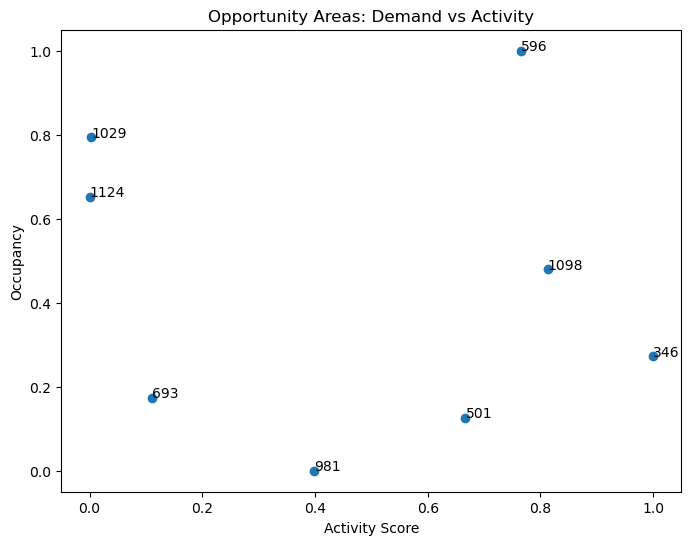

In [88]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    score_df["activity_score"],
    score_df["occupancy"]
)

for _, row in score_df.iterrows():
    plt.text(
        row["activity_score"],
        row["occupancy"],
        str(row["TAZID"])
    )

plt.xlabel("Activity Score")
plt.ylabel("Occupancy")
plt.title("Opportunity Areas: Demand vs Activity")

plt.show()

In [89]:
print(map_analysis.shape)
print(map_analysis.columns)

(275, 16)
Index(['OBJECTID', 'TAZID', 'AREA', 'X', 'Y', 'ZONE', 'LENG_ROAD',
       'SHAPE_Leng', 'SHAPE_Area', 'geometry', 'occupancy', 'charge_count',
       'demand_level', 'supply_level', 'type', 'supply_demand_type'],
      dtype='object')


In [90]:
opportunity_area = map_analysis[
    map_analysis["supply_demand_type"] == "高需求低供给"
].copy()

print(opportunity_area.shape)

(8, 16)


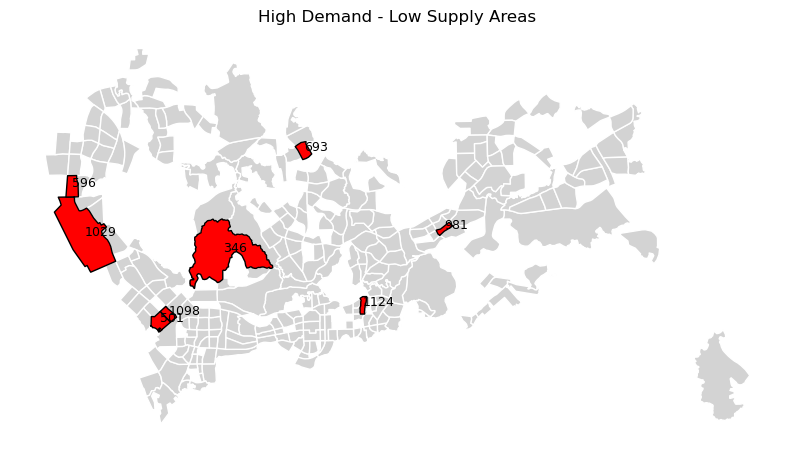

In [91]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 10))

map_analysis.plot(
    ax=ax,
    color="lightgrey",
    edgecolor="white"
)

opportunity_area.plot(
    ax=ax,
    color="red",
    edgecolor="black"
)

for _, row in opportunity_area.iterrows():
    ax.annotate(
        str(row["TAZID"]),
        xy=(row.geometry.centroid.x, row.geometry.centroid.y),
        fontsize=9
    )

ax.set_title("High Demand - Low Supply Areas")
ax.axis("off")

plt.show()

In [92]:
%whos

Variable                   Type            Data/Info
----------------------------------------------------
MinMaxScaler               type            <class 'sklearn.preproces<...>sing._data.MinMaxScaler'>
analysis_df                DataFrame            TAZID   occupancy  c<...>n\n[275 rows x 7 columns]
area_profile               DataFrame            TAZID   occupancy  c<...>\n[275 rows x 10 columns]
avg_charge                 float64         63.75272727272727
avg_occ                    float64         17.86645697304537
ax                         Axes            Axes(0.125,0.288868;0.775x0.412263)
classify                   function        <function classify at 0x000001B6ED330860>
corr                       DataFrame                                <...>.93                1.00  
districts                  GeoDataFrame         OBJECTID  TAZID   AR<...>\n[491 rows x 10 columns]
districts_analysis         GeoDataFrame         OBJECTID  TAZID   AR<...>\n[491 rows x 11 columns]
fig           

In [93]:
opportunity_area_poi = opportunity_area.merge(
    poi_feature,
    on="TAZID",
    how="left"
)

In [94]:
opportunity_area_poi.shape

(8, 19)

In [95]:
opportunity_area_poi

,OBJECTID,TAZID,AREA,X,Y,ZONE,LENG_ROAD,SHAPE_Leng,SHAPE_Area,geometry,occupancy,charge_count,demand_level,supply_level,type,supply_demand_type,business and residential,food and beverage services,lifestyle services
0,18,1098,1.52,113.895982,22.558545,502.0,7.259,5631.958108,1793471.0,"POLYGON ((12679475 2578095, 12679094 2577749, ...",25.844613,60.0,True,False,高需求低供给,高需求低供给,647,565,1652
1,20,501,2.83,113.886244,22.551021,507.0,5.205,8549.662470,3340472.0,"POLYGON ((12677831 2579062, 12679094 2577749, ...",21.692680,47.0,True,False,高需求低供给,高需求低供给,450,449,1791
2,74,981,0.97,114.198879,22.645271,743.0,0.000,5319.744151,1151107.5,"POLYGON ((12712554 2588871, 12712010 2588363, ...",20.212477,49.0,True,False,高需求低供给,高需求低供给,305,483,1119
3,205,1124,1.07,114.109629,22.568022,123.0,5.254,5543.323890,1273211.0,"POLYGON ((12702826 2578753, 12702311 2578747, ...",27.878223,61.0,True,False,高需求低供给,高需求低供给,202,317,578
4,244,1029,29.67,113.803949,22.638996,532.0,3.909,27950.682575,35010826.5,"POLYGON ((12667963 2591373, 12668092 2591372, ...",29.551565,36.0,True,False,高需求低供给,高需求低供给,523,142,686
5,299,346,35.44,113.955844,22.622276,353.0,13.027,40319.911566,41809560.5,"POLYGON ((12685484 2590267, 12685546 2590243, ...",23.417357,61.0,True,False,高需求低供给,高需求低供给,1236,572,1465
6,397,693,2.07,114.044487,22.724681,639.0,5.330,6349.435405,2453342.0,"POLYGON ((12695657 2597765, 12695265 2597633, ...",22.257136,59.0,True,False,高需求低供给,高需求低供给,383,252,853
7,464,596,2.96,113.790366,22.687733,535.0,0.000,7976.528629,3508081.0,"POLYGON ((12667344 2593073, 12667347 2593017, ...",31.966851,55.0,True,False,高需求低供给,高需求低供给,718,588,1373


In [96]:
poi_cols = [
    "business and residential",
    "food and beverage services",
    "lifestyle services"
]


opportunity_area_poi["total_poi"] = (
    opportunity_area_poi[poi_cols]
    .sum(axis=1)
)


for col in poi_cols:
    opportunity_area_poi[col+"_ratio"] = (
        opportunity_area_poi[col] /
        opportunity_area_poi["total_poi"]
    )


opportunity_area_poi[
    [
        "TAZID",
        "business and residential_ratio",
        "food and beverage services_ratio",
        "lifestyle services_ratio"
    ]
].round(2)

,TAZID,business and residential_ratio,food and beverage services_ratio,lifestyle services_ratio
0,1098,0.23,0.20,0.58
1,501,0.17,0.17,0.67
2,981,0.16,0.25,0.59
3,1124,0.18,0.29,0.53
4,1029,0.39,0.11,0.51
5,346,0.38,0.17,0.45
6,693,0.26,0.17,0.57
7,596,0.27,0.22,0.51


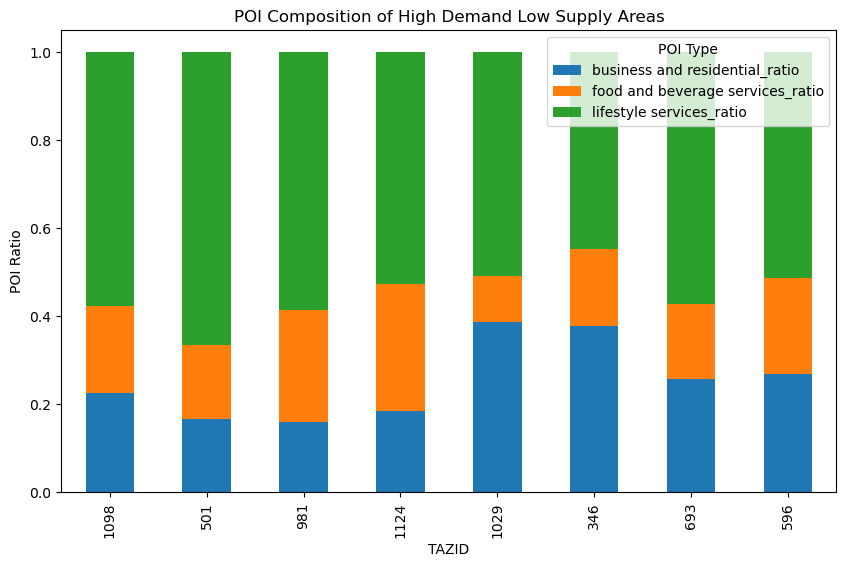

In [97]:
#图：候选区域POI结构堆叠柱状图
plot_df = opportunity_area_poi.set_index("TAZID")[
    [
        "business and residential_ratio",
        "food and beverage services_ratio",
        "lifestyle services_ratio"
    ]
]


plot_df.plot(
    kind="bar",
    stacked=True,
    figsize=(10,6)
)


plt.ylabel("POI Ratio")
plt.xlabel("TAZID")
plt.title("POI Composition of High Demand Low Supply Areas")

plt.legend(
    title="POI Type"
)

plt.show()

In [98]:
area_profile

,TAZID,occupancy,charge_count,demand_level,supply_level,type,supply_demand_type,business and residential,food and beverage services,lifestyle services
0,102,14.207873,30,False,False,低需求低供给,低需求低供给,197,112,631
1,104,1.196478,19,False,False,低需求低供给,低需求低供给,309,466,2313
2,105,17.774056,93,False,True,低需求高供给,低需求高供给,197,416,1261
3,106,49.159876,96,True,True,高需求高供给,高需求高供给,349,375,950
4,107,17.214434,88,False,True,低需求高供给,低需求高供给,152,122,478
...,...,...,...,...,...,...,...,...,...,...
270,1166,23.478591,82,True,True,高需求高供给,高需求高供给,670,475,1712
271,1167,137.304558,373,True,True,高需求高供给,高需求高供给,340,352,957
272,1168,8.238605,43,False,False,低需求低供给,低需求低供给,373,510,965
273,1172,3.131906,9,False,False,低需求低供给,低需求低供给,505,393,1118


In [99]:
area_profile.columns

Index(['TAZID', 'occupancy', 'charge_count', 'demand_level', 'supply_level',
       'type', 'supply_demand_type', 'business and residential',
       'food and beverage services', 'lifestyle services'],
      dtype='object')

In [100]:
#生成聚类类型
poi_cols = [
    "business and residential",
    "food and beverage services",
    "lifestyle services"
]


cluster_df = area_profile[
    [
        "TAZID"
    ] + poi_cols
].copy()


cluster_df.head()

,TAZID,business and residential,food and beverage services,lifestyle services
0,102,197,112,631
1,104,309,466,2313
2,105,197,416,1261
3,106,349,375,950
4,107,152,122,478


In [101]:
cluster_df["total_poi"] = (
    cluster_df[poi_cols]
    .sum(axis=1)
)


for col in poi_cols:
    cluster_df[col+"_ratio"] = (
        cluster_df[col] /
        cluster_df["total_poi"]
    ).round(2)
cluster_df.head()

,TAZID,business and residential,food and beverage services,lifestyle services,total_poi,business and residential_ratio,food and beverage services_ratio,lifestyle services_ratio
0,102,197,112,631,940,0.21,0.12,0.67
1,104,309,466,2313,3088,0.10,0.15,0.75
2,105,197,416,1261,1874,0.11,0.22,0.67
3,106,349,375,950,1674,0.21,0.22,0.57
4,107,152,122,478,752,0.20,0.16,0.64


In [102]:
X = cluster_df[
    [
        "business and residential_ratio",
        "food and beverage services_ratio",
        "lifestyle services_ratio"
    ]
]
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

D:\Anacoda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] 系统找不到指定的文件。
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "D:\Anacoda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "D:\Anacoda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "D:\Anacoda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
              

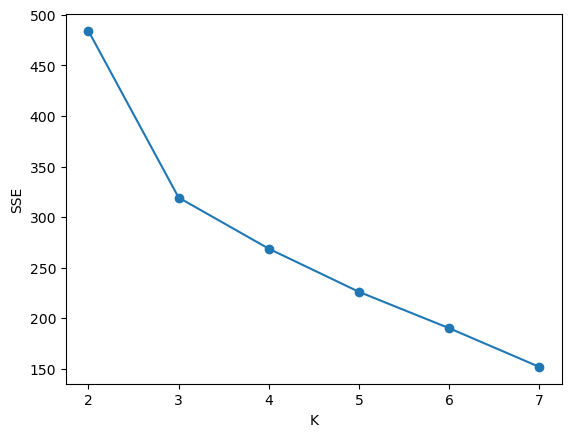

In [103]:
#肘部法 判断k值最佳选择
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt


sse = []

for k in range(2,8):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42
    )

    kmeans.fit(X_scaled)

    sse.append(kmeans.inertia_)


plt.plot(
    range(2,8),
    sse,
    marker="o"
)

plt.xlabel("K")
plt.ylabel("SSE")

plt.show()

In [104]:
from sklearn.cluster import KMeans

# 1. 创建模型
kmeans = KMeans(
    n_clusters=3,
    random_state=42
)

# 2. 聚类预测，给df新增cluster列
cluster_df["cluster"] = kmeans.fit_predict(X_scaled)

# 3. 按簇分组求均值，看每一类特征
cluster_df.groupby("cluster")[
    [
        "business and residential_ratio",
        "food and beverage services_ratio",
        "lifestyle services_ratio"
    ]
].mean().round(2)


D:\Anacoda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


,business and residential_ratio,food and beverage services_ratio,lifestyle services_ratio
cluster,,,
0,0.43,0.14,0.43
1,0.21,0.21,0.58
2,0.20,0.10,0.70


In [105]:
cluster_result = cluster_df[
    [
        "TAZID",
        "cluster"
    ]
]

cluster_result.head()

,TAZID,cluster
0,102,2
1,104,2
2,105,1
3,106,1
4,107,1


In [106]:
analysis_cluster = (
    analysis_df
    .merge(
        cluster_result,
        on="TAZID",
        how="left"
    )
)
analysis_cluster.head()

,TAZID,occupancy,charge_count,demand_level,supply_level,type,supply_demand_type,cluster
0,102,14.207873,30,False,False,低需求低供给,低需求低供给,2
1,104,1.196478,19,False,False,低需求低供给,低需求低供给,2
2,105,17.774056,93,False,True,低需求高供给,低需求高供给,1
3,106,49.159876,96,True,True,高需求高供给,高需求高供给,1
4,107,17.214434,88,False,True,低需求高供给,低需求高供给,1


In [107]:
analysis_cluster[
    analysis_cluster["supply_demand_type"]=="高需求低供给"
].groupby("cluster").size()

cluster
0    2
1    6
dtype: int64

In [108]:
cluster_df.head()

,TAZID,business and residential,food and beverage services,lifestyle services,total_poi,business and residential_ratio,food and beverage services_ratio,lifestyle services_ratio,cluster
0,102,197,112,631,940,0.21,0.12,0.67,2
1,104,309,466,2313,3088,0.10,0.15,0.75,2
2,105,197,416,1261,1874,0.11,0.22,0.67,1
3,106,349,375,950,1674,0.21,0.22,0.57,1
4,107,152,122,478,752,0.20,0.16,0.64,1


In [109]:
cluster_name = {
    0:"商住综合型",
    1:"生活消费混合型",
    2:"生活服务主导型"
}


cluster_df["area_type"] = (
    cluster_df["cluster"]
    .map(cluster_name)
)


cluster_df.head()

,TAZID,business and residential,food and beverage services,lifestyle services,total_poi,business and residential_ratio,food and beverage services_ratio,lifestyle services_ratio,cluster,area_type
0,102,197,112,631,940,0.21,0.12,0.67,2,生活服务主导型
1,104,309,466,2313,3088,0.10,0.15,0.75,2,生活服务主导型
2,105,197,416,1261,1874,0.11,0.22,0.67,1,生活消费混合型
3,106,349,375,950,1674,0.21,0.22,0.57,1,生活消费混合型
4,107,152,122,478,752,0.20,0.16,0.64,1,生活消费混合型


In [110]:
cluster_df[
[
"TAZID",
"cluster",
"area_type"
]
].head()

,TAZID,cluster,area_type
0,102,2,生活服务主导型
1,104,2,生活服务主导型
2,105,1,生活消费混合型
3,106,1,生活消费混合型
4,107,1,生活消费混合型


In [111]:
final_analysis = analysis_df.merge(
    cluster_df[
        [
            "TAZID",
            "area_type"
        ]
    ],
    on="TAZID",
    how="left"
).round(2)
final_analysis.head()

,TAZID,occupancy,charge_count,demand_level,supply_level,type,supply_demand_type,area_type
0,102,14.21,30,False,False,低需求低供给,低需求低供给,生活服务主导型
1,104,1.20,19,False,False,低需求低供给,低需求低供给,生活服务主导型
2,105,17.77,93,False,True,低需求高供给,低需求高供给,生活消费混合型
3,106,49.16,96,True,True,高需求高供给,高需求高供给,生活消费混合型
4,107,17.21,88,False,True,低需求高供给,低需求高供给,生活消费混合型


In [112]:
opportunity_profile = (
    final_analysis[
        final_analysis["supply_demand_type"]=="高需求低供给"
    ]
    ["area_type"]
    .value_counts()
)


opportunity_profile

area_type
生活消费混合型    6
商住综合型      2
Name: count, dtype: int64

In [113]:
#8个充电供需失衡区域中，75%属于生活消费混合型区域，25%属于商住综合型区域，没有出现在生活服务主导型区域。

In [114]:
final_analysis.head()

,TAZID,occupancy,charge_count,demand_level,supply_level,type,supply_demand_type,area_type
0,102,14.21,30,False,False,低需求低供给,低需求低供给,生活服务主导型
1,104,1.20,19,False,False,低需求低供给,低需求低供给,生活服务主导型
2,105,17.77,93,False,True,低需求高供给,低需求高供给,生活消费混合型
3,106,49.16,96,True,True,高需求高供给,高需求高供给,生活消费混合型
4,107,17.21,88,False,True,低需求高供给,低需求高供给,生活消费混合型


In [115]:
opportunity = final_analysis[
    final_analysis["supply_demand_type"]=="高需求低供给"
].copy()

In [116]:
opportunity = final_analysis[
    final_analysis["supply_demand_type"]=="高需求低供给"
].copy()


opportunity.shape

(8, 8)

In [117]:
poi_feature.head()

primary_types,business and residential,food and beverage services,lifestyle services
TAZID,,,
102.0,197,112,631
104.0,309,466,2313
105.0,197,416,1261
106.0,349,375,950
107.0,152,122,478


In [118]:
opportunity_full = opportunity.merge(
    poi_feature,
    on="TAZID",
    how="left"
)

print(opportunity_full.shape)
print(opportunity_full.columns)

(8, 11)
Index(['TAZID', 'occupancy', 'charge_count', 'demand_level', 'supply_level',
       'type', 'supply_demand_type', 'area_type', 'business and residential',
       'food and beverage services', 'lifestyle services'],
      dtype='object')


In [119]:
poi_cols = [
    "business and residential",
    "food and beverage services",
    "lifestyle services"
]

opportunity_full["total_poi"] = (
    opportunity_full[poi_cols].sum(axis=1)
)

opportunity_full[
    ["TAZID", "total_poi"]
]

,TAZID,total_poi
0,346,3273
1,501,2690
2,596,2679
3,693,1488
4,981,1907
5,1029,1351
6,1098,2864
7,1124,1097


In [120]:
map_df[
    ["TAZID", "AREA"]
].head()

,TAZID,AREA
0,1054,11.49
1,1052,17.07
2,850,2.85
3,1066,1.57
4,1068,1.41


In [121]:
opportunity_full = opportunity_full.merge(
    map_df[["TAZID", "AREA"]],
    on="TAZID",
    how="left"
)

print(opportunity_full[["TAZID", "AREA", "total_poi"]])

   TAZID   AREA  total_poi
0    346  35.44       3273
1    501   2.83       2690
2    596   2.96       2679
3    693   2.07       1488
4    981   0.97       1907
5   1029  29.67       1351
6   1098   1.52       2864
7   1124   1.07       1097


In [122]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

opportunity_full["charge_norm"] = (
    scaler.fit_transform(
        opportunity_full[["charge_count"]]
    ).ravel()
)
opportunity_full["poi_density"] = (
    opportunity_full["total_poi"] /
    opportunity_full["AREA"]
)

opportunity_full[
    ["TAZID", "total_poi", "AREA", "poi_density"]
].sort_values(
    "poi_density",
    ascending=False
).round(2)

,TAZID,total_poi,AREA,poi_density
4,981,1907,0.97,1965.98
6,1098,2864,1.52,1884.21
7,1124,1097,1.07,1025.23
1,501,2690,2.83,950.53
2,596,2679,2.96,905.07
3,693,1488,2.07,718.84
0,346,3273,35.44,92.35
5,1029,1351,29.67,45.53


In [123]:
opportunity_full["supply_gap"] = (1 - opportunity_full["charge_norm"])

In [124]:
opportunity_full[
    ["TAZID", "occupancy", "charge_count", "supply_gap", "poi_density"]
]

,TAZID,occupancy,charge_count,supply_gap,poi_density
0,346,23.42,61,0.00,92.353273
1,501,21.69,47,0.56,950.530035
2,596,31.97,55,0.24,905.067568
3,693,22.26,59,0.08,718.840580
4,981,20.21,49,0.48,1965.979381
5,1029,29.55,36,1.00,45.534210
6,1098,25.84,60,0.04,1884.210526
7,1124,27.88,61,0.00,1025.233645


In [125]:
from sklearn.preprocessing import MinMaxScaler

scaler_occ = MinMaxScaler()

opportunity_full["demand_score"] = (
    scaler_occ.fit_transform(
        opportunity_full[["occupancy"]]
    ).ravel()
)


In [126]:
scaler_poi = MinMaxScaler()

opportunity_full["activity_score"] = (
    scaler_poi.fit_transform(
        opportunity_full[["poi_density"]]
    ).ravel()
)

In [127]:
opportunity_full[
    [
        "TAZID",
        "demand_score",
        "supply_gap",
        "activity_score"
    ]
].round(2)

,TAZID,demand_score,supply_gap,activity_score
0,346,0.27,0.00,0.02
1,501,0.13,0.56,0.47
2,596,1.00,0.24,0.45
3,693,0.17,0.08,0.35
4,981,0.00,0.48,1.00
5,1029,0.79,1.00,0.00
6,1098,0.48,0.04,0.96
7,1124,0.65,0.00,0.51


In [128]:
score_features = opportunity_full[
    [
        "TAZID",
        "demand_score",
        "supply_gap",
        "activity_score"
    ]
].copy()

score_features.round(2)

,TAZID,demand_score,supply_gap,activity_score
0,346,0.27,0.00,0.02
1,501,0.13,0.56,0.47
2,596,1.00,0.24,0.45
3,693,0.17,0.08,0.35
4,981,0.00,0.48,1.00
5,1029,0.79,1.00,0.00
6,1098,0.48,0.04,0.96
7,1124,0.65,0.00,0.51


In [129]:
score_features = opportunity_full[
    [
        "TAZID",
        "demand_score",
        "supply_gap",
        "activity_score"
    ]
].copy()

feature_cols = [
    "demand_score",
    "supply_gap",
    "activity_score"
]

P = score_features[feature_cols].div(
    score_features[feature_cols].sum(axis=0),
    axis=1
)

P.round(4)

,demand_score,supply_gap,activity_score
0,0.0780,0.0000,0.0065
1,0.0360,0.2333,0.1253
2,0.2859,0.1000,0.1190
3,0.0498,0.0333,0.0932
4,0.0000,0.2000,0.2659
5,0.2270,0.4167,0.0000
6,0.1368,0.0167,0.2545
7,0.1864,0.0000,0.1356


In [130]:
print(P.shape)

(8, 3)


In [131]:
P.round(4)

,demand_score,supply_gap,activity_score
0,0.0780,0.0000,0.0065
1,0.0360,0.2333,0.1253
2,0.2859,0.1000,0.1190
3,0.0498,0.0333,0.0932
4,0.0000,0.2000,0.2659
5,0.2270,0.4167,0.0000
6,0.1368,0.0167,0.2545
7,0.1864,0.0000,0.1356


In [132]:
P.sum(axis=0)

demand_score      1.0
supply_gap        1.0
activity_score    1.0
dtype: float64

In [133]:
import numpy as np

n = len(P)
k = 1 / np.log(n)

E = -k * (
    P.where(P > 0)
     .apply(lambda col: (col * np.log(col)).sum())
)

E
#熵值：E 熵值越低，差异性越高

demand_score      0.840605
supply_gap        0.691582
activity_score    0.836201
dtype: float64

In [134]:
d = 1 - E
d.round(4)

demand_score      0.1594
supply_gap        0.3084
activity_score    0.1638
dtype: float64

In [135]:
weights = d / d.sum()
weights.round(4)

demand_score      0.2524
supply_gap        0.4883
activity_score    0.2593
dtype: float64

In [136]:
d = 1 - E
print("差异系数：")
print(d.round(4))

weights = d / d.sum()
print("\n熵权法权重：")
print(weights.round(4))

差异系数：
demand_score      0.1594
supply_gap        0.3084
activity_score    0.1638
dtype: float64

熵权法权重：
demand_score      0.2524
supply_gap        0.4883
activity_score    0.2593
dtype: float64


In [137]:
score_features["opportunity_score"] = (
    score_features["demand_score"] * weights["demand_score"]
    + score_features["supply_gap"] * weights["supply_gap"]
    + score_features["activity_score"] * weights["activity_score"]
)

In [138]:
result = score_features.sort_values(
    "opportunity_score",
    ascending=False
)

result[
    [
        "TAZID",
        "demand_score",
        "supply_gap",
        "activity_score",
        "opportunity_score"
    ]
].round(3)

,TAZID,demand_score,supply_gap,activity_score,opportunity_score
5,1029,0.794,1.00,0.000,0.689
4,981,0.000,0.48,1.000,0.494
2,596,1.000,0.24,0.448,0.486
1,501,0.126,0.56,0.471,0.427
6,1098,0.479,0.04,0.957,0.389
7,1124,0.652,0.00,0.510,0.297
3,693,0.174,0.08,0.351,0.174
0,346,0.273,0.00,0.024,0.075


In [139]:
#等权重对照组
score_features["equal_weight_score"] = (
    score_features["demand_score"] / 3
    + score_features["supply_gap"] / 3
    + score_features["activity_score"] / 3
)

equal_result = score_features.sort_values(
    "equal_weight_score",
    ascending=False
)

equal_result[
    [
        "TAZID",
        "demand_score",
        "supply_gap",
        "activity_score",
        "opportunity_score",
        "equal_weight_score"
    ]
].round(3)

,TAZID,demand_score,supply_gap,activity_score,opportunity_score,equal_weight_score
5,1029,0.794,1.00,0.000,0.689,0.598
2,596,1.000,0.24,0.448,0.486,0.563
4,981,0.000,0.48,1.000,0.494,0.493
6,1098,0.479,0.04,0.957,0.389,0.492
7,1124,0.652,0.00,0.510,0.297,0.387
1,501,0.126,0.56,0.471,0.427,0.386
3,693,0.174,0.08,0.351,0.174,0.202
0,346,0.273,0.00,0.024,0.075,0.099


In [140]:
#建立最终表
final_opportunity = score_features[
    [
        "TAZID",
        "demand_score",
        "supply_gap",
        "activity_score",
        "opportunity_score",
        "equal_weight_score"
    ]
].copy()

In [141]:
final_opportunity = final_opportunity.merge(
    opportunity_full[
        [
            "TAZID",
            "occupancy",
            "charge_count",
            "area_type",
            "poi_density"
        ]
    ],
    on="TAZID",
    how="left"
)

In [142]:
final_opportunity["priority_rank"] = (
    final_opportunity["opportunity_score"]
    .rank(
        ascending=False,
        method="min"
    )
    .astype(int)
)

In [143]:
final_opportunity = final_opportunity.sort_values(
    "priority_rank"
)

final_opportunity.round(3)

,TAZID,demand_score,supply_gap,activity_score,opportunity_score,equal_weight_score,occupancy,charge_count,area_type,poi_density,priority_rank
5,1029,0.794,1.00,0.000,0.689,0.598,29.55,36,商住综合型,45.534,1
4,981,0.000,0.48,1.000,0.494,0.493,20.21,49,生活消费混合型,1965.979,2
2,596,1.000,0.24,0.448,0.486,0.563,31.97,55,生活消费混合型,905.068,3
1,501,0.126,0.56,0.471,0.427,0.386,21.69,47,生活消费混合型,950.530,4
6,1098,0.479,0.04,0.957,0.389,0.492,25.84,60,生活消费混合型,1884.211,5
7,1124,0.652,0.00,0.510,0.297,0.387,27.88,61,生活消费混合型,1025.234,6
3,693,0.174,0.08,0.351,0.174,0.202,22.26,59,生活消费混合型,718.841,7
0,346,0.273,0.00,0.024,0.075,0.099,23.42,61,商住综合型,92.353,8


In [144]:
final_opportunity[
    [
        "priority_rank",
        "TAZID",
        "occupancy",
        "charge_count",
        "poi_density",
        "opportunity_score",
        "equal_weight_score",
        "area_type"
    ]
].sort_values("priority_rank").round(2)

,priority_rank,TAZID,occupancy,charge_count,poi_density,opportunity_score,equal_weight_score,area_type
5,1,1029,29.55,36,45.53,0.69,0.60,商住综合型
4,2,981,20.21,49,1965.98,0.49,0.49,生活消费混合型
2,3,596,31.97,55,905.07,0.49,0.56,生活消费混合型
1,4,501,21.69,47,950.53,0.43,0.39,生活消费混合型
6,5,1098,25.84,60,1884.21,0.39,0.49,生活消费混合型
7,6,1124,27.88,61,1025.23,0.30,0.39,生活消费混合型
3,7,693,22.26,59,718.84,0.17,0.20,生活消费混合型
0,8,346,23.42,61,92.35,0.08,0.10,商住综合型


In [151]:

final_opportunity = final_opportunity.round(2)

final_opportunity.to_csv(
    "../dataset/UrbanEV/final_opportunity.csv",
    index=False,
    encoding="utf-8-sig"
)


In [152]:
pd.read_csv(
    "../dataset/UrbanEV/final_opportunity.csv"
).round(2).head()

,TAZID,demand_score,supply_gap,activity_score,opportunity_score,equal_weight_score,occupancy,charge_count,area_type,poi_density,priority_rank
0,1029,0.79,1.00,0.00,0.69,0.60,29.55,36,商住综合型,45.53,1
1,981,0.00,0.48,1.00,0.49,0.49,20.21,49,生活消费混合型,1965.98,2
2,596,1.00,0.24,0.45,0.49,0.56,31.97,55,生活消费混合型,905.07,3
3,501,0.13,0.56,0.47,0.43,0.39,21.69,47,生活消费混合型,950.53,4
4,1098,0.48,0.04,0.96,0.39,0.49,25.84,60,生活消费混合型,1884.21,5
